[107.00058539 112.76193846  87.85557794 ... 126.36013317 134.92674338
  95.3315074 ]


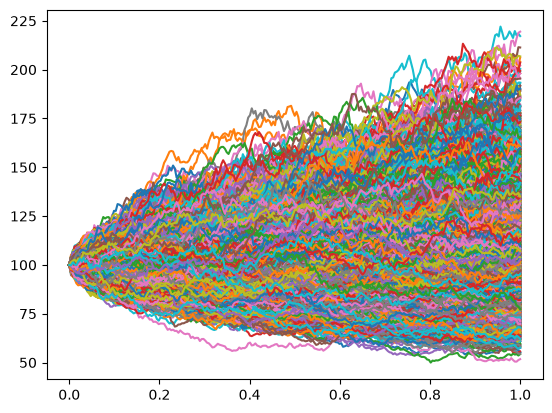

In [ ]:
import random 
import numpy as np 
import scipy
import math
import matplotlib.pyplot as plt

T = 1
n= 252
m=10000
dt = T/n
S0 = 100
mu = 0.08
sigma = 0.2

rng = np.random.default_rng(42)

Z = rng.standard_normal((n,m))
dW = Z*np.sqrt(dt)
W = np.cumsum(dW, axis = 0)
A = np.zeros((1,m))
W_t = np.concatenate((A,W))

time = np.linspace(0,1,n+1)
t = time.reshape(-1,1)

S_t = S0 * np.exp((mu-(sigma**2)/2)*t + sigma*W_t)
S1 = S_t[-1]
plt.plot(t,S_t)
print(S1)


108.53251877400673 106.27132899130885


(array([1.19256797e-04, 2.38513595e-04, 2.98141994e-04, 1.43108157e-03,
        2.38513595e-03, 3.42863293e-03, 5.33674169e-03, 6.38023867e-03,
        9.39147280e-03, 1.12995816e-02, 1.32673187e-02, 1.55630121e-02,
        1.78587054e-02, 1.88425740e-02, 1.99158852e-02, 1.89618308e-02,
        1.75903776e-02, 1.79183338e-02, 1.58015257e-02, 1.43108157e-02,
        1.44897009e-02, 1.16573520e-02, 1.12399532e-02, 9.39147280e-03,
        7.84113444e-03, 5.96283987e-03, 5.54544108e-03, 4.59138670e-03,
        3.01123414e-03, 3.13049093e-03, 2.11680816e-03, 1.96773716e-03,
        1.58015257e-03, 1.40126737e-03, 9.54054380e-04, 5.96283987e-04,
        5.96283987e-04, 4.77027190e-04, 2.98141994e-04, 1.49070997e-04,
        1.49070997e-04, 1.49070997e-04, 1.19256797e-04, 8.94425981e-05,
        8.94425981e-05, 5.96283987e-05, 5.96283987e-05, 2.98141994e-05,
        0.00000000e+00, 5.96283987e-05]),
 array([ 51.74394866,  55.09805516,  58.45216167,  61.80626817,
         65.16037467,  68.5144

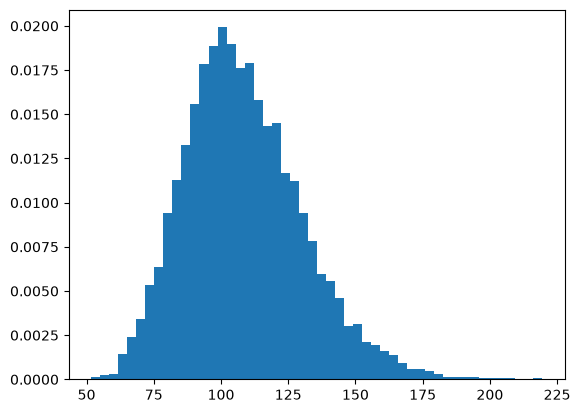

In [30]:
mean = np.mean(S1)
median = np.median(S1)
print(mean,median)
plt.hist(S1,bins=50, density=True)


(array([0.00346065, 0.00692131, 0.01038196, 0.01384262, 0.02076392,
        0.02076392, 0.06575243, 0.10381962, 0.15572943, 0.16957205,
        0.25954905, 0.32876213, 0.3910539 , 0.46718829, 0.59523249,
        0.85824219, 0.8651635 , 1.16277974, 1.20084693, 1.46385664,
        1.65419261, 1.7753155 , 1.94142689, 2.01410062, 1.93104492,
        1.94142689, 1.99679735, 1.71648438, 1.71302372, 1.6472713 ,
        1.4361714 , 1.33235179, 1.07972404, 0.97590442, 0.77172584,
        0.6090751 , 0.49141287, 0.35990801, 0.29761624, 0.20763924,
        0.21109989, 0.10381962, 0.09689831, 0.03114589, 0.03806719,
        0.02076392, 0.02076392, 0.01730327, 0.00346065, 0.00692131]),
 array([-0.65886269, -0.62996642, -0.60107015, -0.57217388, -0.54327761,
        -0.51438133, -0.48548506, -0.45658879, -0.42769252, -0.39879624,
        -0.36989997, -0.3410037 , -0.31210743, -0.28321115, -0.25431488,
        -0.22541861, -0.19652234, -0.16762607, -0.13872979, -0.10983352,
        -0.08093725, -0.05

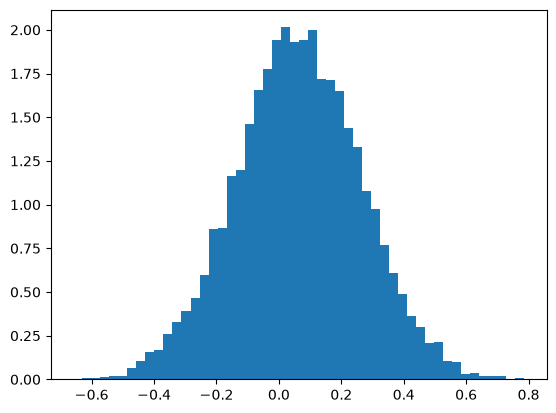

In [31]:
plt.hist(np.log(S1/S0), bins=50, density=True)

104.2768978426669
100.18814219480002


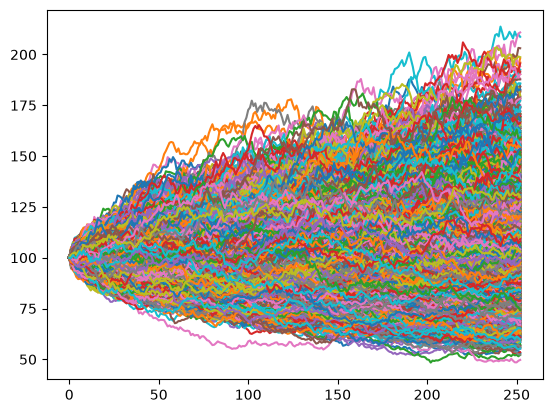

In [35]:
T = 1
n= 252
m=10000
dt = T/n
S0 = 100
r = 0.04
sigma = 0.2

rng = np.random.default_rng(42)

Z = rng.standard_normal((n,m))
dW = Z*np.sqrt(dt)
W = np.cumsum(dW, axis = 0)
A = np.zeros((1,m))
W_t = np.concatenate((A,W))

time = np.linspace(0,1,n+1)
t = time.reshape(-1,1)

S_t = S0 * np.exp((r-(sigma**2)/2)*t + sigma*W_t)
S1 = S_t[-1]


plt.plot(S_t)
print(np.mean(S1))
print(np.exp(-r)*np.mean(S1))

In [56]:
import sys
sys.path.append("..")
from src.bounds import call_bounds
from src.payoffs import call_payoff, put_payoff
from src.parity import parity_gap


T = 1
n= 1
m=10000000
dt = T/n
S0 = 100
r = 0.04
sigma = 0.4
K = 100

rng = np.random.default_rng(42)

Z = rng.standard_normal((n,m))
dW = Z*np.sqrt(dt)
W = np.cumsum(dW, axis = 0)
A = np.zeros((1,m))
W_t = np.concatenate((A,W))

time = np.linspace(0,1,n+1)
t = time.reshape(-1,1)

S_t = S0 * np.exp((r-(sigma**2)/2)*t + sigma*W_t)
S1 = S_t[-1]

c_payoff = call_payoff(S1,K)
p_payoff = put_payoff(S1,K)
call_mean = np.mean(c_payoff)
put_mean = np.mean(p_payoff)
C = np.exp(-r*T)*call_mean
P = np.exp(-r*T)*put_mean
print(C)
print(P)

print(call_bounds(S0,K,r,T))

print(parity_gap(C,P,S0,K,r,T))




17.572132944644856
13.653053920342897
(np.float64(3.9210560847676845), 100)
-0.00197706046571966
